# Magnitudes magnéticas, marco y procedencia

**Nivel 1 · Prerrequisitos: ninguno; lectura: 30 minutes.**

## Objetivos

Distinga el campo inductor total de la anomalía secundaria, registre marco ENU y unidades, e inspeccione la procedencia antes de interpretar un levantamiento magnético.

## Preparación

Use el entorno de notebooks Python 3.12 revisado del repositorio. Este notebook no instala dependencias. El fixture protocolario versionado declara un campo de referencia uniforme y un payload serializado de valores cero. No es respuesta magnética medida y no debe graficarse ni interpretarse como levantamiento.

La celda siguiente inspecciona el objeto protocolario serializado y reporta su contrato geométrico.

In [1]:
import runpy
from pathlib import Path

# Leer el fixture protocolario creado; su payload cero no es una medición física.
root = Path.cwd().parents[2]
soporte = runpy.run_path(str(root / 'tests/data/magnetic_survey_support.py'))
solicitud = soporte['request']()
adq = solicitud['acquisition']
geometria = solicitud['geometry']
print({'tipo_fuente': solicitud['source']['kind'], 'ejes': solicitud['frame']['axes'],
       'unidad_coordenadas': solicitud['frame']['coordinate_unit'],
       'magnitud_observada': solicitud['observations']['quantity'],
       'unidad_observada': solicitud['observations']['unit'],
       'forma_payload': solicitud['observations']['values']['shape'],
       'campo_inductor_nT': solicitud['inducing_field']['F_nT'],
       'grupos_de_vuelo': len(set(adq['group_ids'])), 'campos_geometria': sorted(geometria)})

{'tipo_fuente': 'authored_synthetic', 'ejes': 'ENU', 'unidad_coordenadas': 'm', 'magnitud_observada': 'secondary_enu_nT', 'unidad_observada': 'nT', 'forma_payload': [288, 3], 'campo_inductor_nT': 50000.0, 'grupos_de_vuelo': 12, 'campos_geometria': ['mesh', 'partition', 'qc_reason', 'receivers_m', 'usable']}


## Datos

El fixture protocolario versionado declara un campo de referencia uniforme y un payload serializado de valores cero. No es respuesta magnética medida y no debe graficarse ni interpretarse como levantamiento.

**Archivos:** `tests/data/magnetic_survey_support.py`, `tests/fixtures/magnetic_survey/generate.py`.

## Método

En un marco ENU, x apunta al este, y al norte y z hacia arriba. El vector inductor es B₀=F(cos I sin D, cos I cos D, −sin I), con declinación D horaria desde el norte e inclinación I positiva hacia abajo. Para un campo secundario débil b, la anomalía lineal de campo total aproxima f·b; la magnitud exacta |B₀+b|−F puede diferir. Esta distinción corresponde al contexto de modelado de campos potenciales ([Cockett et al., 2015](https://doi.org/10.1016/j.cageo.2015.09.015)); no convierte un payload sintético nulo en evidencia observacional.

El fixture fija ejes ENU locales, coordenadas en metros, IDs de filas y campo de referencia uniforme. Con I positiva hacia abajo y D horaria desde el norte, f=(cos I sin D, cos I cos D, −sin I); la componente este depende de declinación y la componente vertical es negativa para inclinación positiva hacia abajo. B₀=Ff tiene componentes en nT. Para vector secundario b, la proyección f·b produce la anomalía de campo total de primer orden; la magnitud exacta |B₀+b|−F incluye términos de curvatura del orden |b|²/F. Ambas magnitudes usan nT, pero representan observables distintos.

Antes de interpretar un campo, establezca si b es residual medido, producto procesado o control sintético; registre modelo/época de fondo, marco, unidades, linaje de correcciones y derechos. Aquí las 288 filas son geometría creada, el campo inductor es supuesto uniforme explícito y la respuesta serializada vale cero. La figura muestra solo altitud de receptores y componentes del vector declarado. No debe leerse como mapa de anomalía, estimación IGRF ni evidencia de magnetización nula.

## Resultados

La celda informa procedencia de esquema, marco, unidades y forma del arreglo; no amplitud de anomalía ni calidad de inversión. El payload protocolario no contiene respuesta medida.

Graficar coordenadas protocolarias en metros y el campo uniforme declarado en nT. Como el payload de respuesta es exactamente cero por construcción, no se muestra campo de respuesta magnética ni resultado de inversión.


norma del vector unitario ENU: 0.9999999999999999 máximo abs. payload respuesta [nT]: 0.0


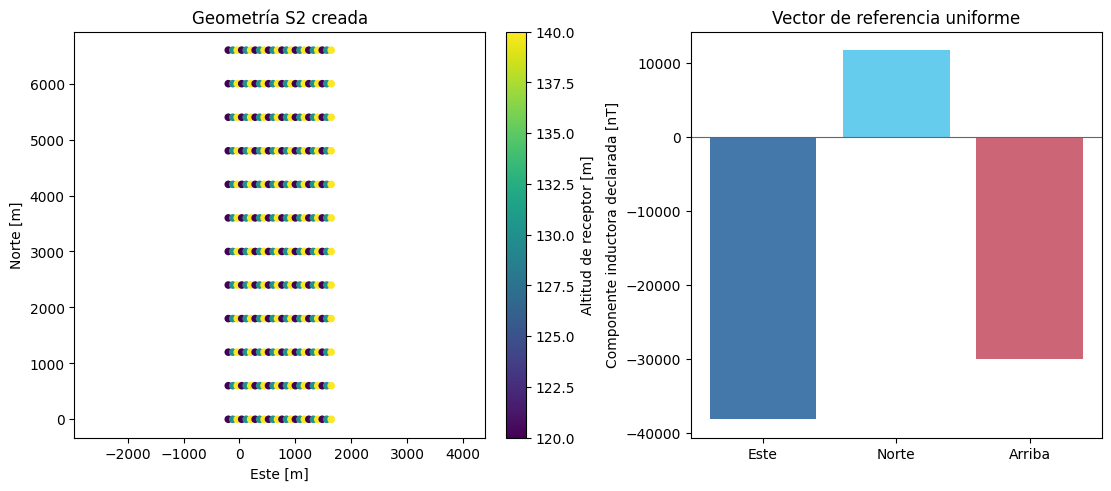

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Graficar geometría de líneas creada y vector de campo declarado; no interpretar el payload nulo como datos.
xyz=np.asarray(geometria['receivers_m']['data'],dtype=float).reshape(-1,3); campo=solicitud['inducing_field']
i,d=np.deg2rad([campo['I_deg'],campo['D_deg']]); f=np.array([np.cos(i)*np.sin(d),np.cos(i)*np.cos(d),-np.sin(i)]); B0=campo['F_nT']*f
fig,(ax,bx)=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)
sc=ax.scatter(xyz[:,0],xyz[:,1],c=xyz[:,2],cmap='viridis',s=20)
ax.set(xlabel='Este [m]',ylabel='Norte [m]',title='Geometría S2 creada'); ax.set_aspect('equal',adjustable='datalim'); fig.colorbar(sc,ax=ax,label='Altitud de receptor [m]')
bx.bar(['Este','Norte','Arriba'],B0,color=['#4477aa','#66ccee','#cc6677']); bx.axhline(0,color='.4',lw=.8)
bx.set(ylabel='Componente inductora declarada [nT]',title='Vector de referencia uniforme')
print('norma del vector unitario ENU:',np.linalg.norm(f),'máximo abs. payload respuesta [nT]:',max(abs(x) for x in solicitud['observations']['values']['data']))
plt.show()


## Resumen

Mantenga marco, convención de campo, derechos de fuente y procedencia de observaciones unidos a todo producto magnético.


## Referencias

- https://doi.org/10.1016/j.cageo.2015.09.015